In [1]:
from utils import load_splits, tokenize_dataset, compute_metrics
import torch
import pandas as pd

/home/default/projects/fake_news_classification/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#global random seed
SEED = 42
torch.manual_seed(SEED)

In [3]:
X_train, X_val, X_test, y_train, y_val, y_test = load_splits()

1
2
3


In [16]:
df_test = pd.merge(X_test, y_test, left_index=True, right_index=True)
df_test

,title,labels
0,German Vice-Chancellor: EU Breaking Apart ’No ...,0
1,The most predictable disaster in the history o...,0
2,"South Sudan government, rebel groups sign ceas...",0
3,Trump administration open to additional strike...,0
4,Border Patrol Agent Died after Being Stabbed b...,0
...,...,...
9328,Two Of Trump’s Top Picks Accused Of Violently...,1
9329,Catholic Church: It Is Not ‘Necessary’ For Bi...,1
9330,Turkey’s Crackdown on Criticism Continues as J...,1
9331,#TrumpSacrifices: Twitter DESTROYS Trump For ...,1


In [4]:
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

True
NVIDIA GeForce RTX 3050 6GB Laptop GPU


device(type='cuda')

In [5]:
import glob
import json
from pathlib import Path
logs = {}
for file in Path("logs").glob("*json"):
    with open(file, "r", encoding = "utf-8") as f:
        logs[f.name[5:-3]] = json.load(f)
        

In [6]:
logs

{'bert-base-uncased_1e-05.j': [{'epoch': 1.0,
   'grad_norm': 0.45982691645622253,
   'learning_rate': 1e-05,
   'loss': 1.8025546989763128,
   'step': 2723,
   'eval_accuracy': 0.9368906032358298,
   'eval_f1_macro': 0.9363577362317469,
   'eval_loss': 0.18825526535511017,
   'eval_precision_macro': 0.9351364491644607,
   'eval_recall_macro': 0.9383330507810208,
   'eval_runtime': 54.4626,
   'eval_samples_per_second': 171.365,
   'eval_steps_per_second': 42.855},
  {'epoch': 2.0,
   'grad_norm': 34.70402145385742,
   'learning_rate': 1e-05,
   'loss': 1.3708847555832262,
   'step': 5446,
   'eval_accuracy': 0.9418193506910961,
   'eval_f1_macro': 0.9408112799883533,
   'eval_loss': 0.2971939444541931,
   'eval_precision_macro': 0.9434225434416619,
   'eval_recall_macro': 0.9389273173466692,
   'eval_runtime': 51.5175,
   'eval_samples_per_second': 181.162,
   'eval_steps_per_second': 45.305},
  {'epoch': 3.0,
   'grad_norm': 0.005152707453817129,
   'learning_rate': 1e-05,
   'loss':

In [7]:
val_metrics = []
for k, log in logs.items():
    if isinstance(log, list):
        for epoch in log:
            epoch["model"] = f"{k[:10]}"
            val_metrics.append(epoch)
            #val_metrics[f"{k}_epoch_{epoch["epoch"]:.0f}"] = epoch
    else:
        val_metrics.append(log)
        log["model"] = "tfidf"


In [8]:
val = pd.DataFrame(val_metrics)

val = val.sort_values("model").reset_index(drop=True)

val = val.drop(columns=["grad_norm", "step", "eval_runtime", "eval_samples_per_second", "eval_steps_per_second"])

val

,epoch,learning_rate,loss,eval_accuracy,eval_f1_macro,eval_loss,eval_precision_macro,eval_recall_macro,model
0,1.0,0.000010,1.802555,0.936891,0.936358,0.188255,0.935136,0.938333,bert-base-
1,2.0,0.000010,1.370885,0.941819,0.940811,0.297194,0.943423,0.938927,bert-base-
2,3.0,0.000010,1.002502,0.944927,0.944246,0.325295,0.944162,0.944332,bert-base-
3,4.0,0.000010,0.692068,0.944498,0.943774,0.365882,0.943997,0.943560,bert-base-
4,5.0,0.000010,0.412077,0.943641,0.942894,0.413880,0.943211,0.942595,bert-base-
5,1.0,0.000030,1.732809,0.940641,0.940198,0.204087,0.938879,0.942746,bert-base-
6,2.0,0.000030,1.294750,0.945784,0.945010,0.290406,0.945843,0.944282,bert-base-
7,3.0,0.000030,0.693395,0.946105,0.945512,0.395418,0.944904,0.946214,bert-base-
8,4.0,0.000030,0.279815,0.947284,0.946620,0.442291,0.946641,0.946598,bert-base-
9,5.0,0.000030,0.086357,0.946212,0.945574,0.529658,0.945289,0.945876,bert-base-


In [10]:
val["display_name"] = (
    val["model"].map(lambda x: x[0]) +"_lr_" + val["learning_rate"].map(lambda x: format(x, ".0e"))
    + "_e_" + val["epoch"].astype("Int64").astype(str)
).fillna("baseline")

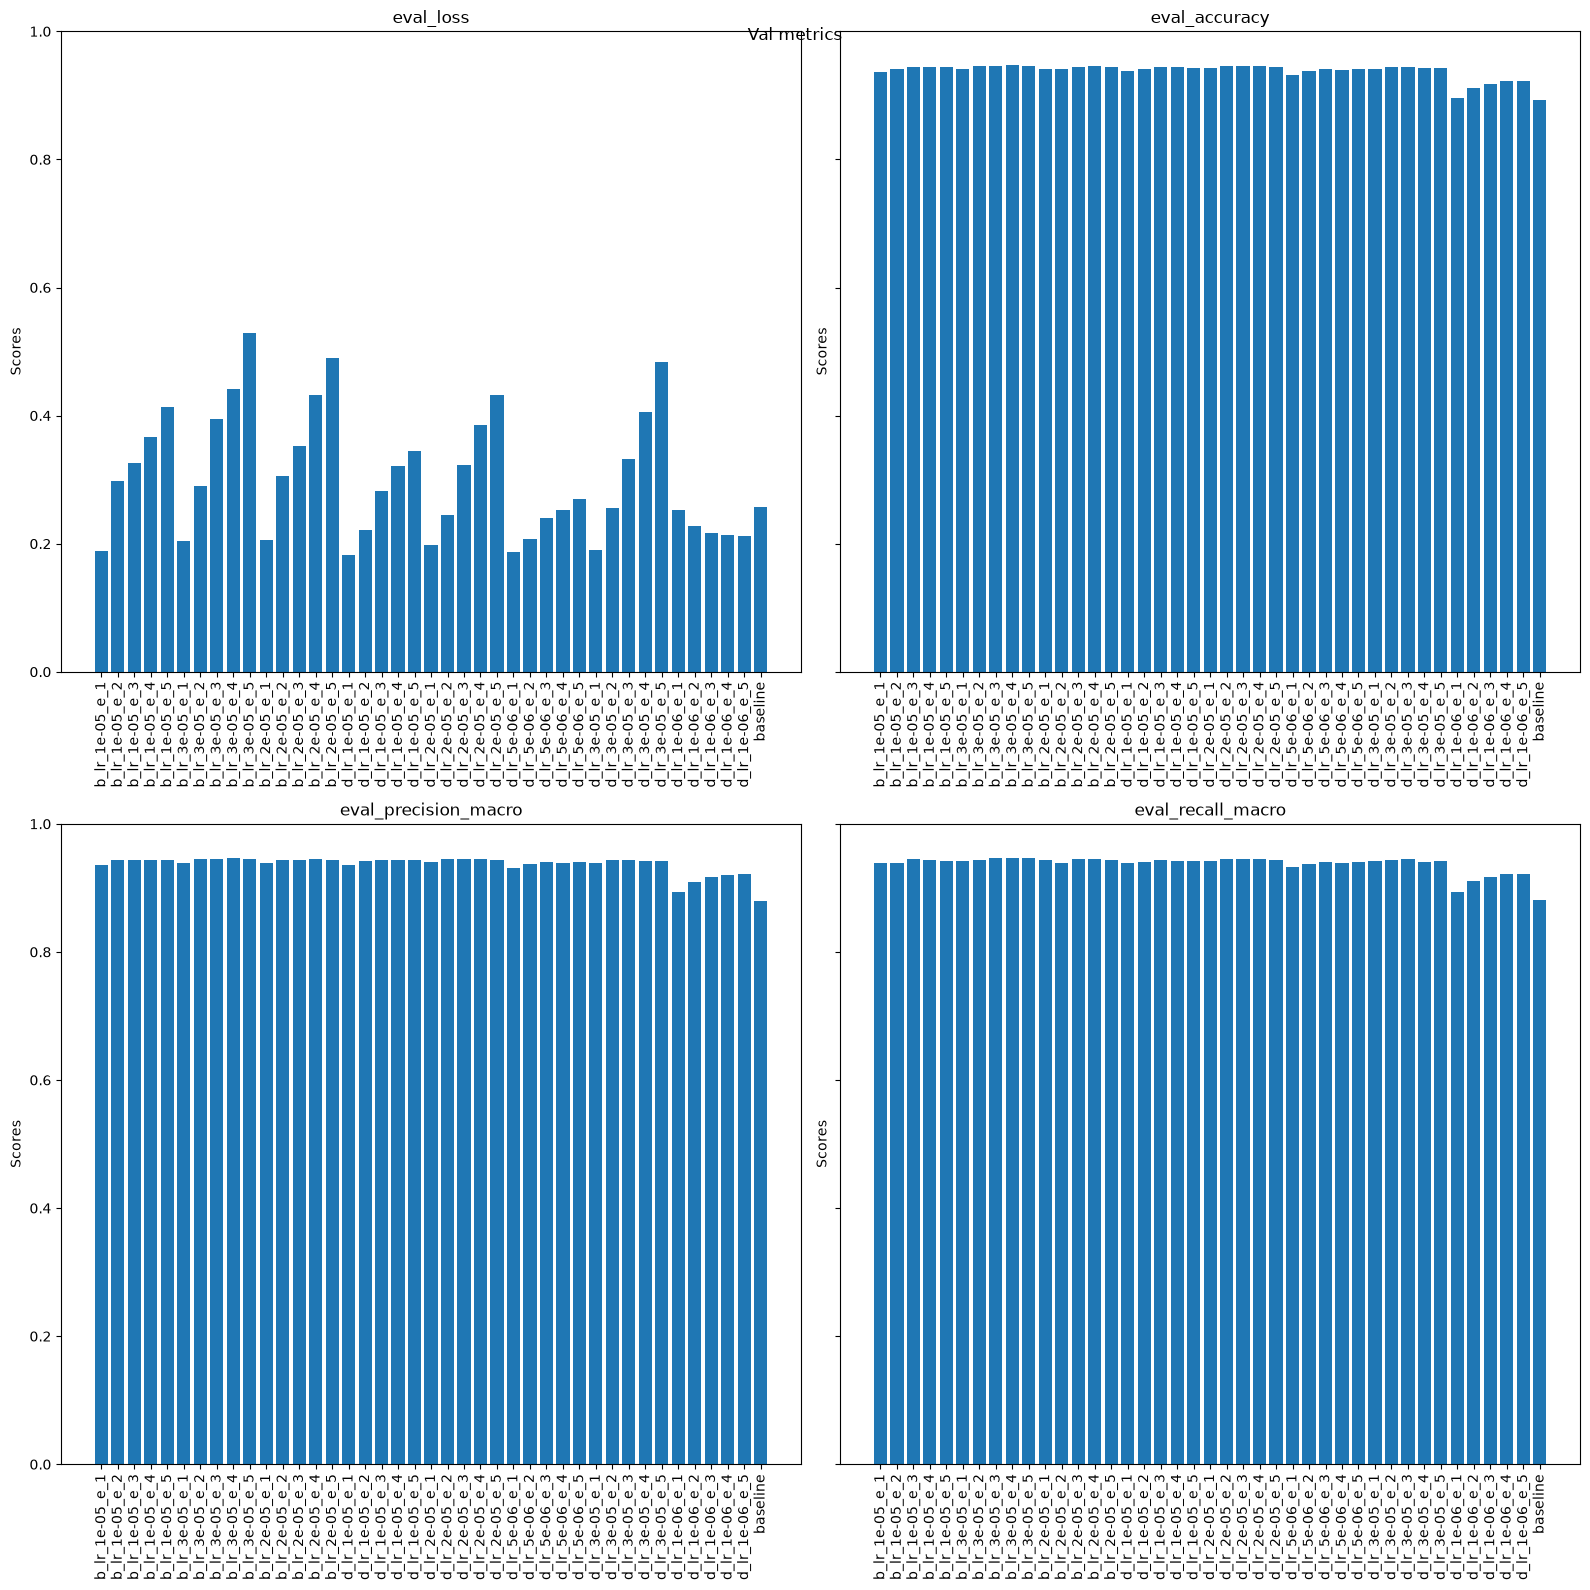

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2,2, figsize = (16,16), sharey = True)

metrics = ['eval_loss', 'eval_accuracy', 'eval_precision_macro', 'eval_recall_macro']


for index, metric in enumerate(metrics):
    i = index // 2
    j = index % 2

    axes[i, j].bar(val["display_name"], val[metric])
    axes[i,j].set_title(metric)
    axes[i,j].set_ylim(0,1)
    axes[i,j].set_ylabel('Scores')
    axes[i,j].tick_params(axis="x", labelrotation=90)
plt.tight_layout()
fig.suptitle("Val metrics")
plt.show()



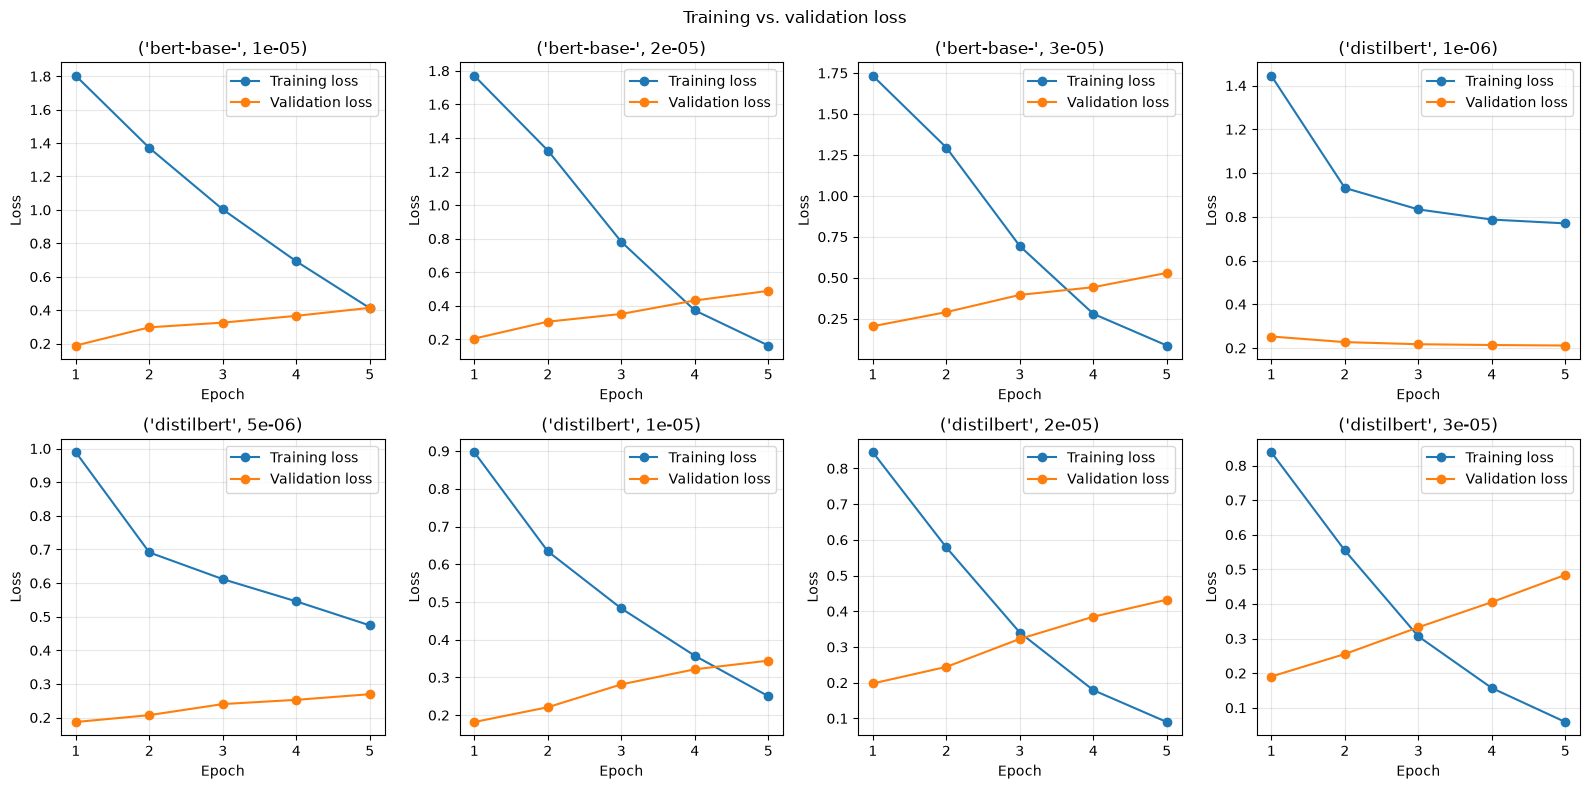

In [107]:
loss_val = val.dropna(subset=["loss", "eval_loss"]).copy()
loss_val = loss_val.sort_values(["model", "epoch"])

groups = list(loss_val.groupby(["model", "learning_rate"], sort=True))
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for ax, (model_name, group) in zip(axes, groups):
    ax.plot(group["epoch"], group["loss"], marker="o", label="Training loss")
    ax.plot(group["epoch"], group["eval_loss"], marker="o", label="Validation loss")
    ax.set_title(model_name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.3)
    ax.legend()

for ax in axes[len(groups):]:
    ax.set_visible(False)

fig.suptitle("Training vs. validation loss")
plt.tight_layout()
plt.show()


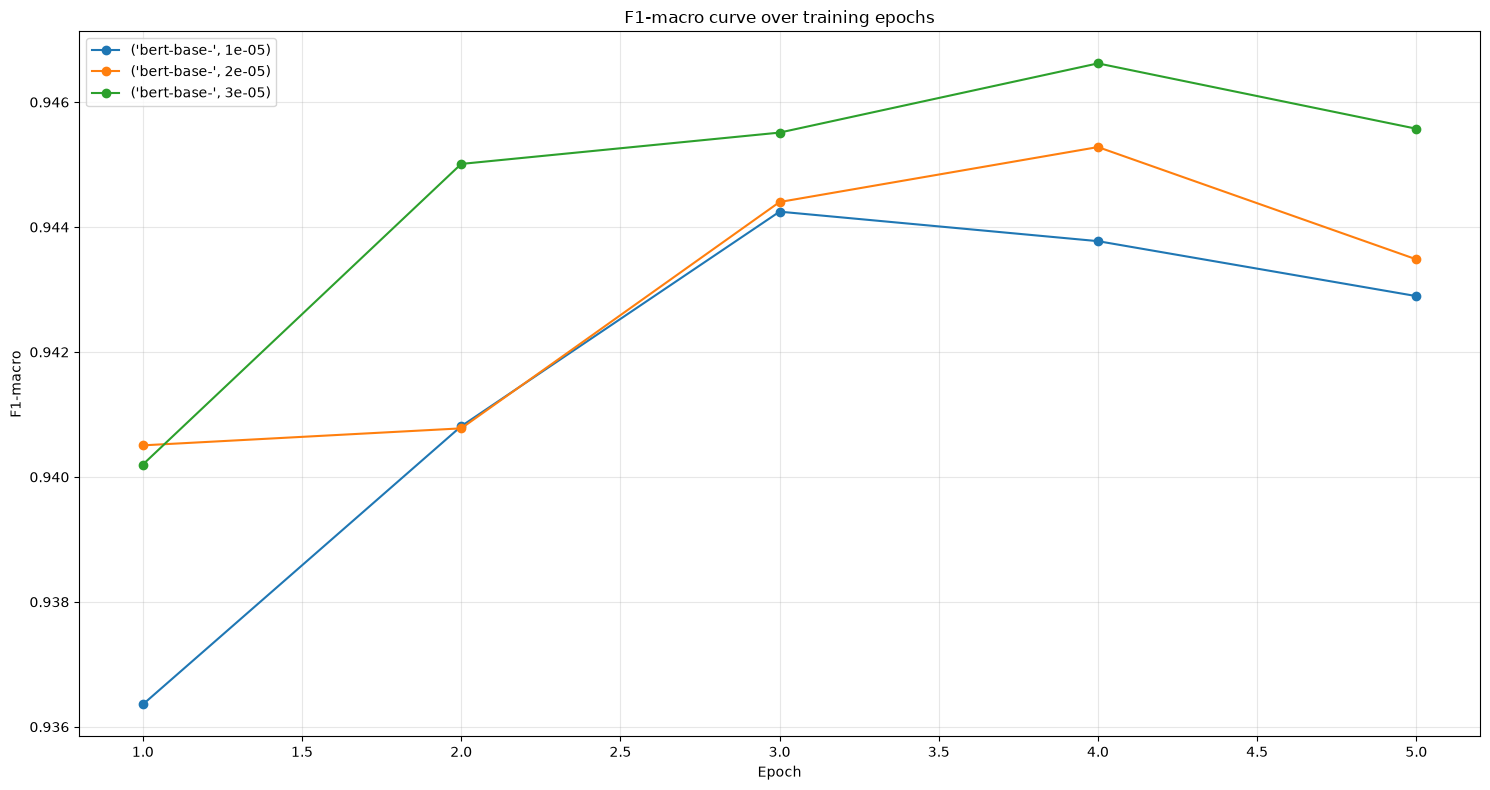

In [ ]:
f1_macro_val = val[val["model"]=="bert-base-"].dropna(subset=["loss", "eval_loss"]).copy()
f1_macro_val = f1_macro_val.sort_values(["model", "epoch"])

groups = list(f1_macro_val.groupby(["model", "learning_rate"], sort=True))
fig, ax = plt.subplots(figsize=(15, 8))


for (model_name, group) in groups:
    ax.plot(group["epoch"], group["eval_f1_macro"], marker="o", label=f"{model_name}")
ax.set_title('BERT F1-macro curve over training epochs')
ax.set_xlabel("Epoch")
ax.set_ylabel("F1-macro")
ax.grid(alpha=0.3)
ax.legend()

for ax in axes[len(groups):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

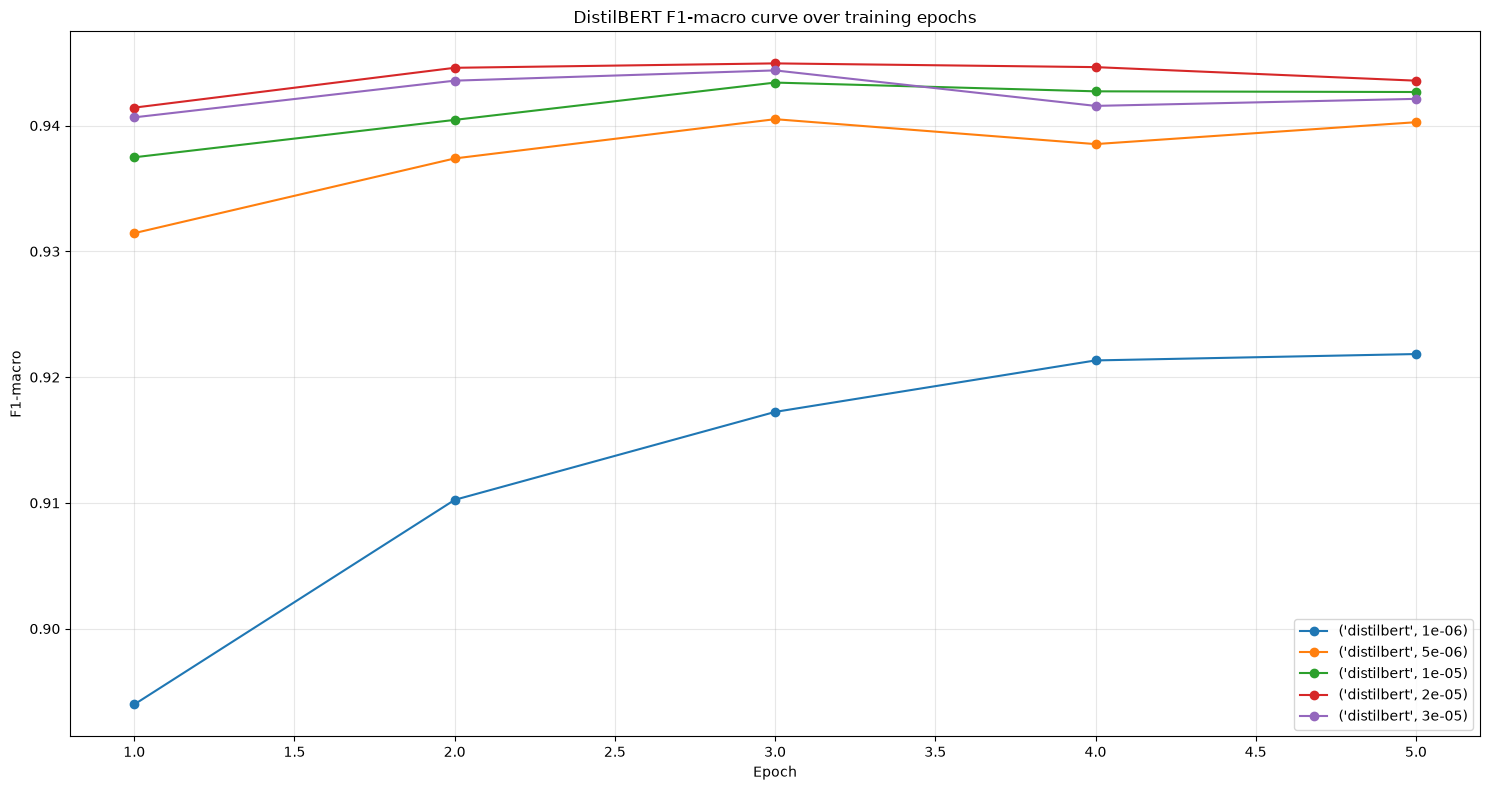

In [109]:
f1_macro_val = val[val["model"]=="distilbert"].dropna(subset=["loss", "eval_loss"]).copy()
f1_macro_val = f1_macro_val.sort_values(["model", "epoch"])

groups = list(f1_macro_val.groupby(["model", "learning_rate"], sort=True))
fig, ax = plt.subplots(figsize=(15, 8))


for (model_name, group) in groups:
    ax.plot(group["epoch"], group["eval_f1_macro"], marker="o", label=f"{model_name}")
ax.set_title('DistilBERT F1-macro curve over training epochs')
ax.set_xlabel("Epoch")
ax.set_ylabel("F1-macro")
ax.grid(alpha=0.3)
ax.legend()

for ax in axes[len(groups):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

In [26]:
distilbert = val[val["model"] == "distilbert"]
best_distil =distilbert[(distilbert["eval_f1_macro"]==distilbert["eval_f1_macro"].max())]
bert = val[val["model"] == "bert-base-"]
best_bert = bert[(bert["eval_f1_macro"]==bert["eval_f1_macro"].max())]

selected = pd.concat([best_bert, best_distil])

selected

,epoch,learning_rate,loss,eval_accuracy,eval_f1_macro,eval_loss,eval_precision_macro,eval_recall_macro,model,display_name
8,4.0,0.00003,0.279815,0.947284,0.946620,0.442291,0.946641,0.946598,bert-base-,b_lr_3e-05_e_4
22,3.0,0.00002,0.340316,0.945677,0.944945,0.322631,0.945373,0.944548,distilbert,d_lr_2e-05_e_3


In [28]:
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
)
selected_models = [("bert-base-uncased_1e-05", 10892), ("distilbert-base-uncased_2e-05", 8169)]

predictions = {}
for model_name, checkpoint in selected_models:
    checkpoint_path = f"models/{model_name}/checkpoint-{checkpoint}"
    
    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint_path
    )
    ds_test = tokenize_dataset(X_test, y_test, model_name[:-6])

    tokenizer = AutoTokenizer.from_pretrained(model_name[:-6])

    trainer = Trainer(
        model=model,
        args=TrainingArguments(
            output_dir=f"evaluation/{model_name}",
            per_device_eval_batch_size=8,
            report_to="none",
        ),
        processing_class=tokenizer,
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=compute_metrics,
    )
    predictions[model_name] = trainer.predict(ds_test)

Map: 100%|██████████| 9333/9333 [00:03<00:00, 2489.15 examples/s]


Map: 100%|██████████| 9333/9333 [00:00<00:00, 19360.15 examples/s]


In [36]:
import joblib

baseline_model = joblib.load("models/logistic_regression.pkl")

In [37]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss
results = []
for model_name, prediction in predictions.items():
    metrics = prediction.metrics
    metrics["model_name"] = model_name
    results.append(metrics)

metrics = pd.DataFrame(results)


y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)
baseline_metrics = {
    "model_name" : "baseline",
    "test_accuracy" : accuracy_score(y_pred, y_test),
    "test_precision_macro" : precision_score(y_pred, y_test),
    "test_recall_macro" : recall_score(y_pred, y_test),
    "test_f1_macro" : f1_score(y_pred, y_test),
    "test_loss" : log_loss(y_test, y_prob),
}
results.append(baseline_metrics)


metrics = pd.DataFrame(results)

In [38]:
metrics

,test_loss,test_model_preparation_time,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_runtime,test_samples_per_second,test_steps_per_second,model_name
0,0.346197,0.0063,0.946534,0.946742,0.944904,0.945753,45.1200,206.849,25.864,bert-base-uncased_1e-05
1,0.301387,0.0025,0.947498,0.948201,0.945457,0.946682,25.9801,359.236,44.919,distilbert-base-uncased_2e-05
2,0.256972,NaN,0.893710,0.877231,0.882767,0.879990,NaN,NaN,NaN,baseline
